# PlayNow: prototipo de recomendación contextual de biblioteca

Este cuaderno es la Actividad 2.3. Recomienda **qué juego de los que ya tienes** abrir ahora, no cuál comprar.

El código corre sobre CSV reproducibles. Steam, PlayStation, Xbox, la agenda y el wearable están **simulados**. Los títulos son reales. Los atributos profundos son estimaciones de diseño, no mediciones de laboratorio. El corpus de foros es sintético y sale de la misma ficha. La columna de respuesta galvánica es un proxy calculado desde la HRV, no un segundo sensor.

Semilla fija: 42. El orden lo calcula el motor.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "playnow").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from playnow.engine import (
    SEED,
    INTENTION_TARGETS,
    PlayNowEngine,
    fatigue_from_wearable,
    lexicon_scores,
)

DATA = ROOT / "data"
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 120)
print("semilla", SEED)

semilla 42


## 1. Dataset profundo

La biblioteca de cada persona está en `biblioteca_usuario.csv`. El catálogo caracteriza títulos para todo el mundo, pero el motor solo ordena juegos que esa persona posee.

In [2]:
catalog = pd.read_csv(DATA / "catalogo_videojuegos_profundo.csv")
comments = pd.read_csv(DATA / "comentarios_foros_videojuegos.csv")
users = pd.read_csv(DATA / "usuarios_perfiles_ocupacionales.csv")
library = pd.read_csv(DATA / "biblioteca_usuario.csv")
sessions = pd.read_csv(DATA / "sesiones_contextuales_wearable.csv")

print(f"juegos={len(catalog)} comentarios={len(comments)} usuarios={len(users)} filas_biblioteca={len(library)} sesiones={len(sessions)}")
print("perfiles", users["perfil_ocupacional"].value_counts().to_dict())
print("eventos de cierre", sessions["evento_cierre"].value_counts().to_dict())
catalog[["titulo", "genero", "es_indie", "minutos_hasta_diversion", "duracion_minima_sesion_min", "carga_cognitiva", "valencia", "arousal", "cuadrante", "mu_relajacion", "mu_historia", "score_post_trabajo"]].head(8)

juegos=68 comentarios=136 usuarios=15 filas_biblioteca=109 sesiones=58
perfiles {'alta_carga': 6, 'fin_de_semana': 5, 'competitivo': 4}
eventos de cierre {'GUARDADO_FIN_NATURAL': 44, 'SALIDA_PREMATURA_FRUSTRACION': 8, 'CAMBIO_JUEGO': 6}


,titulo,genero,es_indie,minutos_hasta_diversion,duracion_minima_sesion_min,carga_cognitiva,valencia,arousal,cuadrante,mu_relajacion,mu_historia,score_post_trabajo
0,Hades,roguelike,1,3,20,0.45,0.35,0.75,HVHA,0.10,0.25,0.500
1,Stardew Valley,simulacion,1,5,20,0.25,0.70,-0.55,HVLA,0.90,0.20,0.917
2,Elden Ring,accion-rpg,0,15,45,0.70,-0.20,0.55,LVHA,0.05,0.35,0.500
3,Baldur's Gate 3,rpg,0,25,75,0.80,0.40,0.15,HVHA,0.15,0.95,0.175
4,Rocket League,deportes,0,1,15,0.30,0.25,0.85,HVHA,0.05,0.00,0.500
5,Cyberpunk 2077,rpg,0,20,50,0.55,0.10,0.35,HVHA,0.10,0.85,0.175
6,Celeste,plataformas,1,2,20,0.40,0.15,0.40,HVHA,0.15,0.40,0.500
7,Slay the Spire,roguelike,1,4,25,0.65,0.20,-0.10,HVLA,0.35,0.10,0.500


## 2. Léxico de foros (etiquetado implícito)

Cada comentario es inventado. El generador lo redacta a partir de los mismos atributos de la ficha (carga, duración, costo de retomar y frustración) y el léxico vuelve a contar esas frases: si sirve después del trabajo, si se retoma fácil y si genera frustración. Esos tres puntajes entran al vector de contenido. No son reseñas de jugadores ni un raspado de Reddit o de Steam.

In [3]:
sample = comments.groupby("game_id", as_index=False).first().head(3)
scored = sample.copy()
scored["lexico"] = scored["texto"].map(lambda text: lexicon_scores(text))
for row in scored.itertuples(index=False):
    print(row.game_id)
    print(row.texto)
    print(row.lexico)
    print("---")

assert comments["fuente"].eq("corpus_sintetico").all()
assert catalog["fuente_atributos"].eq("estimacion_de_diseno_no_medicion").all()

amongus
Se puede abrir un rato, aunque no es la opción más suave. Retomar fácil, controles simples, se vuelve a entrar y no olvidas los controles. Se siente justo y se puede dejar sin castigo.
{'score_post_trabajo': 0.5, 'score_facil_retomar': 0.9, 'score_juego_confort': 1.0, 'riesgo_frustracion_lexico': 0.0}
---
animal
Ideal después del trabajo, partida corta para desconectar cuando llego cansado, sin pensar mucho. Retomar fácil, controles simples, se vuelve a entrar y no olvidas los controles. Se siente justo y se puede dejar sin castigo.
{'score_post_trabajo': 0.917, 'score_facil_retomar': 0.9, 'score_juego_confort': 1.0, 'riesgo_frustracion_lexico': 0.0}
---
baba
Se puede abrir un rato, aunque no es la opción más suave. Retomar fácil, controles simples, se vuelve a entrar y no olvidas los controles. Se siente justo y se puede dejar sin castigo.
{'score_post_trabajo': 0.5, 'score_facil_retomar': 0.9, 'score_juego_confort': 1.0, 'riesgo_frustracion_lexico': 0.0}
---


## 3. Plano de Russell y familias con K-Means

K-Means, con PCA al 95% de varianza y el método del codo, **nombra familias**. No ordena el top. Ordenar por cercanía al centroide reproduciría el sesgo de hubness.

k elegido 5
 k    inertia
 2 599.826601
 3 432.432218
 4 337.725417
 5 268.196689
 6 225.768693
 7 193.951504
 8 176.984079
 9 157.616835
10 137.017698


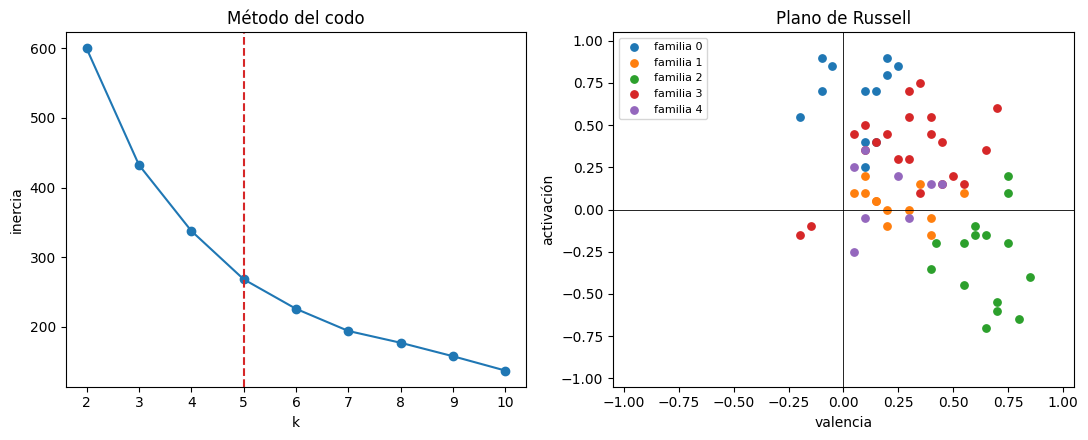

,ejemplos
cluster_id,
0,"Elden Ring, Rocket League, Celeste, Hollow Knight"
1,"Slay the Spire, Civilization VI, Portal 2, Baba Is You"
2,"Stardew Valley, Forza Horizon 5, Unpacking, A Short Hike"
3,"Hades, Vampire Survivors, God of War, Among Us"
4,"Baldur's Gate 3, Cyberpunk 2077, Disco Elysium, Red Dead Redemption 2"


In [4]:
engine = PlayNowEngine(catalog, library, users, sessions)
print("k elegido", int(engine.cluster_model.n_clusters))
print(engine.elbow.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(engine.elbow["k"], engine.elbow["inertia"], marker="o")
axes[0].axvline(engine.cluster_model.n_clusters, color="tab:red", linestyle="--")
axes[0].set_title("Método del codo")
axes[0].set_xlabel("k")
axes[0].set_ylabel("inercia")

plane = engine.catalog
for cluster_id, group in plane.groupby("cluster_id"):
    axes[1].scatter(group["valencia"], group["arousal"], s=28, label=f"familia {cluster_id}")
axes[1].axhline(0, color="black", linewidth=0.6)
axes[1].axvline(0, color="black", linewidth=0.6)
axes[1].set_xlim(-1.05, 1.05)
axes[1].set_ylim(-1.05, 1.05)
axes[1].set_xlabel("valencia")
axes[1].set_ylabel("activación")
axes[1].set_title("Plano de Russell")
axes[1].legend(fontsize=8, loc="best")
fig.tight_layout()
plt.show()

plane.groupby("cluster_id")["titulo"].apply(lambda titles: ", ".join(titles.head(4))).to_frame("ejemplos")

## 4. Motor difuso de la sesión

Minutos libres y fatiga (HR, HRV y sueño, contra la línea base de Andrés) producen la carga cognitiva admisible. Funciones trapezoidales y centroide, como en la práctica de lógica difusa.

In [5]:
andres_baseline = float(users.loc[users["user_id"] == "U01", "hr_baseline"].iloc[0])
contexts = [
    ("Martes 21:30, relajarme", 35, 92, 28, 4.5, "relajarme"),
    ("Sábado 16:00, historia", 180, 66, 52, 8.0, "historia"),
    ("Viernes 20:00, reto", 50, 78, 40, 6.5, "reto"),
]
rows = []
for label, minutes, hr, hrv, sleep, intention in contexts:
    fatigue = fatigue_from_wearable(hr, hrv, sleep, andres_baseline)
    load = engine.fuzzy.admissible_load(minutes, fatigue)
    rows.append({
        "contexto": label,
        "minutos": minutes,
        "fatiga": round(fatigue, 1),
        "carga_admisible": round(load, 3),
        "intencion": INTENTION_TARGETS[intention]["label"],
    })
pd.DataFrame(rows)

,contexto,minutos,fatiga,carga_admisible,intencion
0,"Martes 21:30, relajarme",35,78.1,0.160,Relajarme / Desconectar
1,"Sábado 16:00, historia",180,5.6,0.844,Sumergirme en una historia
2,"Viernes 20:00, reto",50,36.6,0.410,Reto exigente / Competitivo


## 5. Criterio de similitud

El candidato es solo la biblioteca de Andrés (U01).

$$
\mathrm{Score}(u,i,c)=\Phi(i,c)\cdot\big(\alpha\,\mathrm{Sim}(i,c)+\beta\,\mathrm{AjusteDifuso}(i,c)+\gamma\,\mathrm{Colab}(u,i)\big)
$$

`Sim` mezcla coseno del vector profundo (0,55) y cercanía en valencia y activación (0,45), y luego ajusta el costo de reenganche. Si ese ajuste resta, `Sim` queda entre 0 y 1. Si es el bono de un bloque largo y poca fatiga, `Sim` puede pasar de 1: el rescate no se pierde cuando el juego ya coincidía con la intención. Si hay al menos dos juegos con sesiones de vecinos del mismo perfil, los pesos son 0,55, 0,30 y 0,15. Si no, gamma pasa a 0. El vecino solo aporta si el juego ya pertenece a la intención (membresía difusa de al menos 0,45). Así no entra un juego de baja carga en una sesión de historia solo porque un colega lo cerró bien.

In [6]:
def show(ranking, k=3):
    columns = ["puesto", "titulo", "score", "horas_jugadas", "phi_viabilidad", "similitud", "ajuste_difuso", "score_colaborativo", "penalizacion_reenganche", "explicacion"]
    return ranking[columns].head(k)

baseline = engine.baseline("U01")
print("Línea base por horas (igual en los tres contextos)")
print(baseline.head(5).to_string(index=False))

owned_ids = set(library.loc[library["user_id"] == "U01", "game_id"])
rankings = {}
for label, minutes, hr, hrv, sleep, intention in contexts:
    fatigue = fatigue_from_wearable(hr, hrv, sleep, andres_baseline)
    ranking = engine.rank("U01", minutes, fatigue, intention)
    assert set(ranking["game_id"]).issubset(owned_ids)
    rankings[intention] = ranking
    print("\n==", label, "==")
    print(show(ranking).drop(columns=["explicacion"]).to_string(index=False))
    print(ranking.iloc[0]["explicacion"])
    print("métricas", engine.list_metrics(ranking))

Línea base por horas (igual en los tres contextos)
 puesto game_id          titulo  horas_jugadas  dias_sin_jugar  es_indie
      1   hades           Hades            140               2         1
      2    civ6 Civilization VI             48              15         0
      3 stardew  Stardew Valley             36               1         1
      4  rocket   Rocket League             32               5         0
      5   elden      Elden Ring             28              24         0

== Martes 21:30, relajarme ==
 puesto         titulo  score  horas_jugadas  phi_viabilidad  similitud  ajuste_difuso  score_colaborativo  penalizacion_reenganche
      1      Unpacking 0.9291              0          1.0000     0.8788         0.9997               0.972                   0.0000
      2 Stardew Valley 0.8367             36          0.9238     0.9784         0.9103               0.630                   0.0041
      3    Coffee Talk 0.8289              6          1.0000     0.9673         0.98

## 6. El vecino ocupacional mueve el primer puesto

Misma biblioteca y mismo martes. Sin el término colaborativo, el contenido solo no pone primero el juego que los vecinos de alta carga cerraron bien. Con el término, sí. La matriz es pequeña y sintética: esto ilustra el mecanismo, no un filtrado colaborativo a escala.

In [7]:
minutes, hr, hrv, sleep = 35, 92, 28, 4.5
fatigue = fatigue_from_wearable(hr, hrv, sleep, andres_baseline)
with_neighbors = engine.rank("U01", minutes, fatigue, "relajarme", apply_backlog_slot=False)
content_only = engine.rank("U01", minutes, fatigue, "relajarme", apply_backlog_slot=False, use_collaborative=False)
print("Con vecinos", with_neighbors["titulo"].head(3).tolist())
print("Solo contenido", content_only["titulo"].head(3).tolist())
assert with_neighbors.iloc[0]["titulo"] != content_only.iloc[0]["titulo"]

comparison = pd.DataFrame({
    "horas": baseline["titulo"].head(3).tolist(),
    "relajarme": rankings["relajarme"]["titulo"].head(3).tolist(),
    "historia": rankings["historia"]["titulo"].head(3).tolist(),
    "reto": rankings["reto"]["titulo"].head(3).tolist(),
})
comparison

Con vecinos ['Unpacking', 'Stardew Valley', 'Coffee Talk']
Solo contenido ['Coffee Talk', 'Unpacking', 'Stardew Valley']


,horas,relajarme,historia,reto
0,Hades,Unpacking,Baldur's Gate 3,Rocket League
1,Civilization VI,Stardew Valley,Disco Elysium,Hades
2,Stardew Valley,Coffee Talk,The Witcher 3,Celeste


## 7. Lectura de las métricas

Diversidad intra-lista, cobertura del backlog y exposición indie son lecturas de este prototipo. No son un estudio con usuarios reales. La prueba del problema es la tabla anterior: la línea base por horas no cambia entre martes y sábado; PlayNow sí.

In [8]:
summary = []
for intention, ranking in rankings.items():
    metrics = engine.list_metrics(ranking)
    metrics["intencion"] = intention
    metrics["top"] = ", ".join(ranking["titulo"].head(3))
    summary.append(metrics)
pd.DataFrame(summary)[["intencion", "top", "diversidad_intra_lista", "cobertura_backlog", "exposicion_indie"]]

,intencion,top,diversidad_intra_lista,cobertura_backlog,exposicion_indie
0,relajarme,"Unpacking, Stardew Valley, Coffee Talk",0.4400,0.3333,1.0
1,historia,"Baldur's Gate 3, Disco Elysium, The Witcher 3",0.4723,0.0000,1.0
2,reto,"Rocket League, Hades, Celeste",0.4669,0.0000,1.0
